# Appointment no-shows in Brazil

## Introduction

This investigation examines **associations**, rather than causes, between
appointment attendance and three recorded characteristics: age, calendar-day
booking lead time, and SMS receipt. One row represents an appointment; the same
patient can have several appointments. The supplied data contains 110,527
appointments dated April 29–June 8, 2016, from the Brazilian appointment
snapshot supplied by the course. The observation window and clinic population
limit generalization.

The most important reading rule is that **`No-show = Yes` means the patient did
not attend**, whereas `No` means the patient attended. A higher no-show rate
therefore means a larger fraction of appointments were missed.

### Questions

1. How does the distribution of patient age relate to appointment no-show rates?
2. How does calendar-day booking lead time relate to no-show rates?
3. How do the size and no-show rate of the two recorded SMS groups compare?
4. Does the overall SMS comparison persist within lead-time bands, and how do
   age and lead time jointly describe the outcome?

The outcome is a binary appointment-level no-show indicator. The three primary
explanatory variables are age, lead time and SMS receipt. No prediction model,
causal estimate, or significance test is attempted.

### Report navigation

- [Data description and setup](#data-description)
- [Data wrangling](#data-wrangling)
- [Exploratory data analysis](#exploratory-data-analysis)
- [Conclusions](#conclusions)
- [Limitations](#limitations)

<a id="data-description"></a>
### Data description

| Source field | Meaning and use |
|---|---|
| PatientId | Patient identifier; used only to count repeated patients, not as a predictor |
| AppointmentID | Appointment identifier; used to check record uniqueness |
| Gender | Recorded gender; retained as context, not a primary predictor |
| ScheduledDay | Timestamp when the appointment was scheduled |
| AppointmentDay | Appointment date; time of attendance is not supplied |
| Age | Recorded age in years, including infants aged zero |
| Neighbourhood | Recorded clinic/appointment neighbourhood |
| Scholarship | Recorded welfare-program enrollment indicator |
| Hipertension | Recorded hypertension flag; source spelling retained in this dictionary |
| Diabetes | Recorded diabetes flag |
| Alcoholism | Recorded alcoholism flag |
| Handcap | Recorded handicap level; values need not be binary |
| SMS_received | Recorded SMS flag (0 or 1); timing and delivery process are not documented |
| No-show | Recorded attendance label: Yes = missed, No = attended |

The project-provided CSV is the analysis source. The course links the
[original dataset description](https://www.kaggle.com/datasets/joniarroba/noshowappointments).
This report uses only the supplied snapshot. Patient/appointment identifiers
are not displayed in previews or included in the HTML as row-level records.

In [1]:
from pathlib import Path
import hashlib
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display
%matplotlib inline

plt.rcParams.update({
    'figure.dpi': 115, 'font.size': 10, 'axes.titlesize': 12,
    'axes.labelsize': 10, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)
DATA = Path('data/noshowappointments-kagglev2-may-2016.csv')
EXPECTED_SHA256 = '9132d3e7d0246617df9041d3764f20ad6f08e7b0d9f0997fa254fc5e52eda27d'
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == EXPECTED_SHA256
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__} | matplotlib {matplotlib.__version__}')
print('Supplied dataset checksum verified.')

Python 3.13.5 | pandas 3.1.0 | NumPy 2.5.4 | matplotlib 3.11.2
Supplied dataset checksum verified.


<a id="data-wrangling"></a>
## Data Wrangling

### Inspect before changing data

Read identifiers as strings to preserve their source representation. Inspect
shape, datatypes, missingness, duplicate appointments, distributions and date
coverage before choosing cleaning rules. Preview only non-identifier fields.
These checks establish what must be cleaned, rather than assuming the dataset
is already suitable for analysis.

In [2]:
raw = pd.read_csv(DATA, dtype={'PatientId': 'string', 'AppointmentID': 'string'})
print('Rows and columns:', raw.shape)
display(raw.drop(columns=['PatientId', 'AppointmentID']).head())
display(pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(),
                      'distinct': raw.nunique(dropna=False)}))
display(raw[['Age', 'SMS_received']].describe())
print('Exact duplicate rows:', int(raw.duplicated().sum()))
print('Duplicate appointment IDs:', int(raw['AppointmentID'].duplicated().sum()))
print('Unique patient identifiers:', raw['PatientId'].nunique())
print("Additional rows after each patient's first appointment:", int(raw['PatientId'].duplicated().sum()))
display(raw['No-show'].value_counts().rename('appointments').to_frame())

Rows and columns: (110527, 14)


,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


,dtype,missing,distinct
PatientId,string,0,62299
AppointmentID,string,0,110527
Gender,str,0,2
ScheduledDay,str,0,103549
AppointmentDay,str,0,27
Age,int64,0,104
Neighbourhood,str,0,81
Scholarship,int64,0,2
Hipertension,int64,0,2
Diabetes,int64,0,2


,Age,SMS_received
count,110527.000000,110527.000000
mean,37.088874,0.321026
std,23.110205,0.466873
min,-1.000000,0.000000
25%,18.000000,0.000000
50%,37.000000,0.000000
75%,55.000000,1.000000
max,115.000000,1.000000


Exact duplicate rows: 0
Duplicate appointment IDs: 0
Unique patient identifiers: 62299
Additional rows after each patient's first appointment: 48228


,appointments
No-show,
No,88208
Yes,22319


### Cleaning decisions

The raw file has no missing values, no exact duplicate rows, and unique
appointment IDs. It does contain one negative age and five appointment dates
before the scheduling date. These six records are excluded from a common
analysis cohort so that comparisons use consistent denominators. Negative
lead times could represent errors or undocumented changes; their meaning
cannot be resolved here. No values are imputed.

Convert dates with explicit UTC parsing. Because appointment time is not
available, normalize **both** date fields to their encoded calendar dates
before subtraction: a same-day appointment must have a lead time of zero even
if its scheduling timestamp is in the afternoon. This measures calendar-day
lead time, not elapsed hours; the original local timezone is not reconstructed.

Keep age zero and high nonnegative ages, including 115, because the source
does not justify an arbitrary upper-age cutoff. Age bands isolate broad
patterns without asserting a linear relationship. Retain repeat appointments
for a patient because the unit is the appointment. Do not treat those records
as independent people. Rename fields for readability; keep `Handcap` as a
level rather than collapsing its multiple values into a binary variable.

The reusable cleaning and group-rate functions below are also tested in
`tests/test_analysis.py`. Every exclusion is recorded sequentially, so the
removed counts sum exactly to the change in cohort size.

In [3]:
SOURCE_COLUMNS = {'PatientId': 'patient_id',
 'AppointmentID': 'appointment_id',
 'Gender': 'gender',
 'ScheduledDay': 'scheduled_day',
 'AppointmentDay': 'appointment_day',
 'Age': 'age',
 'Neighbourhood': 'neighbourhood',
 'Scholarship': 'scholarship',
 'Hipertension': 'hypertension',
 'Diabetes': 'diabetes',
 'Alcoholism': 'alcoholism',
 'Handcap': 'handicap_level',
 'SMS_received': 'sms_received',
 'No-show': 'no_show_label'}

def clean_appointments(raw):
    """Return one row per usable appointment and sequential exclusion counts."""
    required = {"PatientId", "AppointmentID", "Age", "ScheduledDay",
                "AppointmentDay", "SMS_received", "No-show"}
    if not required.issubset(raw.columns):
        raise ValueError(f"Missing required columns: {sorted(required - set(raw.columns))}")
    labels = set(raw["No-show"].dropna().unique())
    if not labels.issubset({"Yes", "No"}):
        raise ValueError(f"Unexpected No-show labels: {labels}")

    df = raw.rename(columns=SOURCE_COLUMNS).copy()
    audit = [{"rule": "Input appointments", "removed": 0, "remaining": len(df)}]

    def exclude(mask, reason):
        nonlocal df
        removed = int(mask.sum())
        df = df.loc[~mask].copy()
        audit.append({"rule": reason, "removed": removed, "remaining": len(df)})

    exclude(df.duplicated(), "Exact duplicate rows")
    if df["appointment_id"].duplicated().any():
        raise ValueError("Conflicting duplicate appointment IDs require investigation")
    for column in ["scheduled_day", "appointment_day"]:
        df[column] = pd.to_datetime(df[column], utc=True, errors="coerce")
    df["age"] = pd.to_numeric(df["age"], errors="coerce")
    df["sms_received"] = pd.to_numeric(df["sms_received"], errors="coerce")
    critical = ["patient_id", "appointment_id", "age", "scheduled_day",
                "appointment_day", "sms_received", "no_show_label"]
    exclude(df[critical].isna().any(axis=1), "Missing or unparseable critical fields")
    if not df["sms_received"].isin([0, 1]).all():
        raise ValueError("Unexpected SMS_received values")
    exclude(df["age"] < 0, "Negative ages")

    # Appointment timestamps omit appointment time; compare encoded calendar dates.
    df["waiting_days"] = (
        df["appointment_day"].dt.normalize() - df["scheduled_day"].dt.normalize()
    ).dt.days
    exclude(df["waiting_days"] < 0, "Appointment precedes scheduling date")
    df["no_show"] = df["no_show_label"].eq("Yes")
    df["age_band"] = pd.cut(
        df["age"], [0, 18, 35, 50, 65, np.inf], right=False,
        labels=["Under 18", "18-34", "35-49", "50-64", "65+"],
    )
    df["waiting_band"] = pd.cut(
        df["waiting_days"], [-1, 0, 7, 14, 30, 60, np.inf],
        labels=["Same day", "1-7 days", "8-14 days", "15-30 days", "31-60 days", "61+ days"],
    )
    df["sms_group"] = pd.Categorical(
        df["sms_received"].map({0: "No SMS recorded", 1: "SMS recorded"}),
        categories=["No SMS recorded", "SMS recorded"], ordered=True,
    )
    return df.reset_index(drop=True), pd.DataFrame(audit)


def group_rates(df, columns):
    """Keep denominators alongside observed group rates; empty groups stay absent."""
    result = df.groupby(columns, observed=True, dropna=False)["no_show"].agg(
        appointments="size", no_shows="sum", no_show_rate="mean",
    )
    return result.assign(no_show_pct=lambda x: 100 * x["no_show_rate"])


def label_plot(ax, title, xlabel, ylabel):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    return ax

print('Reusable cleaning, rate-table and plot-label helpers defined.')

Reusable cleaning, rate-table and plot-label helpers defined.


In [4]:
appointments, cleaning_audit = clean_appointments(raw)
display(cleaning_audit)
assert len(raw) - cleaning_audit['removed'].sum() == len(appointments)
assert appointments['appointment_id'].is_unique
assert appointments['age'].ge(0).all() and appointments['waiting_days'].ge(0).all()
assert not appointments[['age_band', 'waiting_band', 'sms_group']].isna().any().any()
print('Clean cohort:', len(appointments), 'appointments')
print('Unique patients:', appointments['patient_id'].nunique())
print('Appointment dates:', appointments['appointment_day'].min().date(), 'to', appointments['appointment_day'].max().date())
display(appointments[['age', 'waiting_days']].describe(percentiles=[.25, .5, .75, .95]))
display(appointments[['gender', 'age', 'waiting_days', 'sms_group', 'no_show']].head())

,rule,removed,remaining
0,Input appointments,0,110527
1,Exact duplicate rows,0,110527
2,Missing or unparseable critical fields,0,110527
3,Negative ages,1,110526
4,Appointment precedes scheduling date,5,110521


Clean cohort: 110521 appointments
Unique patients: 62298
Appointment dates: 2016-04-29 to 2016-06-08


,age,waiting_days
count,110521.000000,110521.000000
mean,37.089386,10.184345
std,23.109885,15.255153
min,0.000000,0.000000
25%,18.000000,0.000000
50%,37.000000,4.000000
75%,55.000000,15.000000
95%,75.000000,39.000000
max,115.000000,179.000000


,gender,age,waiting_days,sms_group,no_show
0,F,62,0,No SMS recorded,False
1,M,56,0,No SMS recorded,False
2,F,62,0,No SMS recorded,False
3,F,8,0,No SMS recorded,False
4,F,56,0,No SMS recorded,False


**Cleaning result.** Exactly 6 appointments are excluded,
leaving **110,521 appointments from 62,298 distinct
patient identifiers**. There are 22,314 missed appointments
in this cohort: **20.19%** of all retained appointments. The six excluded
records are too few to dominate overall percentages, but their removal remains
explicit. The data covers scheduled appointments, not all care needs or all
people in the covered population.

<a id="exploratory-data-analysis"></a>
## Exploratory Data Analysis

### 1. Age and appointment attendance

First inspect the outcome balance and age distribution separately. Then compare
no-show rates across age groups. Counts measure workload; rates measure the
fraction missed, so these answer different questions. Group-rate tables retain
both numerators and denominators to avoid mistaking a large group for a high-risk
group. Bands are fixed descriptive choices, not learned thresholds.

,appointments
no_show,
Attended,88207
Missed,22314


,appointments,no_shows,no_show_rate,no_show_pct
age_band,,,,
Under 18,27378,5996,0.22,21.90
18-34,24244,5812,0.24,23.97
35-49,21864,4489,0.21,20.53
50-64,22634,3785,0.17,16.72
65+,14401,2232,0.15,15.50


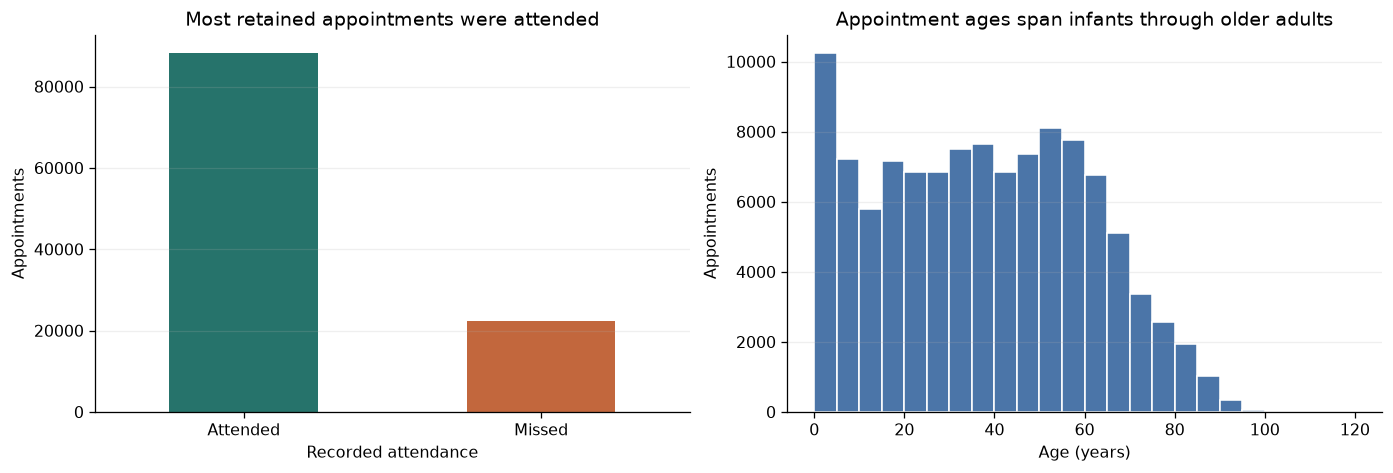

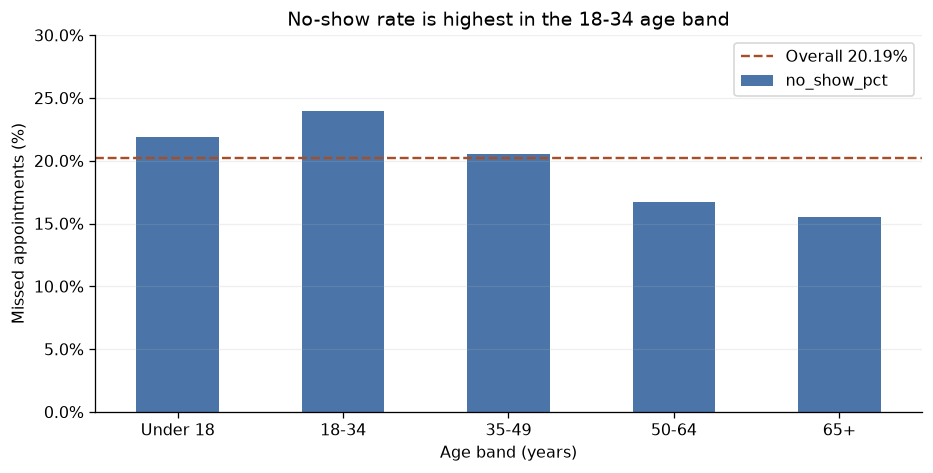

In [5]:
overall_pct = 100 * appointments['no_show'].mean()
outcome_counts = appointments['no_show'].map({False: 'Attended', True: 'Missed'}).value_counts().reindex(['Attended', 'Missed'])
display(outcome_counts.rename('appointments').to_frame())
age_rates = group_rates(appointments, 'age_band')
display(age_rates.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
outcome_counts.plot.bar(ax=axes[0], color=['#26736b', '#c2673d'], rot=0)
label_plot(axes[0], 'Most retained appointments were attended', 'Recorded attendance', 'Appointments')
appointments['age'].plot.hist(ax=axes[1], bins=np.arange(0, 121, 5), color='#4b75a8', edgecolor='white')
label_plot(axes[1], 'Appointment ages span infants through older adults', 'Age (years)', 'Appointments')
fig.savefig(FIGURES / '01_outcome_and_age.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
age_rates['no_show_pct'].plot.bar(ax=ax, color='#4b75a8', rot=0)
ax.axhline(overall_pct, color='#a54e2a', linestyle='--', label=f'Overall {overall_pct:.2f}%')
ax.set_ylim(0, 30)
ax.yaxis.set_major_formatter(PercentFormatter(100))
label_plot(ax, 'No-show rate is highest in the 18-34 age band', 'Age band (years)', 'Missed appointments (%)')
ax.legend()
fig.savefig(FIGURES / '02_age_rates.png', bbox_inches='tight')
plt.show()

**Finding.** The no-show rate is 23.97% for
ages 18–34 and 15.50% for ages 65 and above.
Under-18 appointments have a rate of 21.90%.
Thus the pattern is not simply that the youngest patients miss the most
appointments. These are appointment-weighted associations; age can also relate
to medical need, transport, caregiver support and appointment lead time, none
of which are held constant in this first comparison.

### 2. Booking lead time and attendance

Inspect the full lead-time distribution, including its long tail, and then
compare rates in explicit calendar-day intervals. Same-day appointments are
shown separately because they have substantially less opportunity for plans to
change. The grouped rate plot complements the histogram; a histogram alone
cannot show whether a group has a higher probability of missing an appointment.

,appointments,no_shows,no_show_rate,no_show_pct
waiting_band,,,,
Same day,38562,1792,0.05,4.65
1-7 days,32185,7772,0.24,24.15
8-14 days,12025,3664,0.30,30.47
15-30 days,17371,5661,0.33,32.59
31-60 days,8283,2829,0.34,34.15
61+ days,2095,596,0.28,28.45


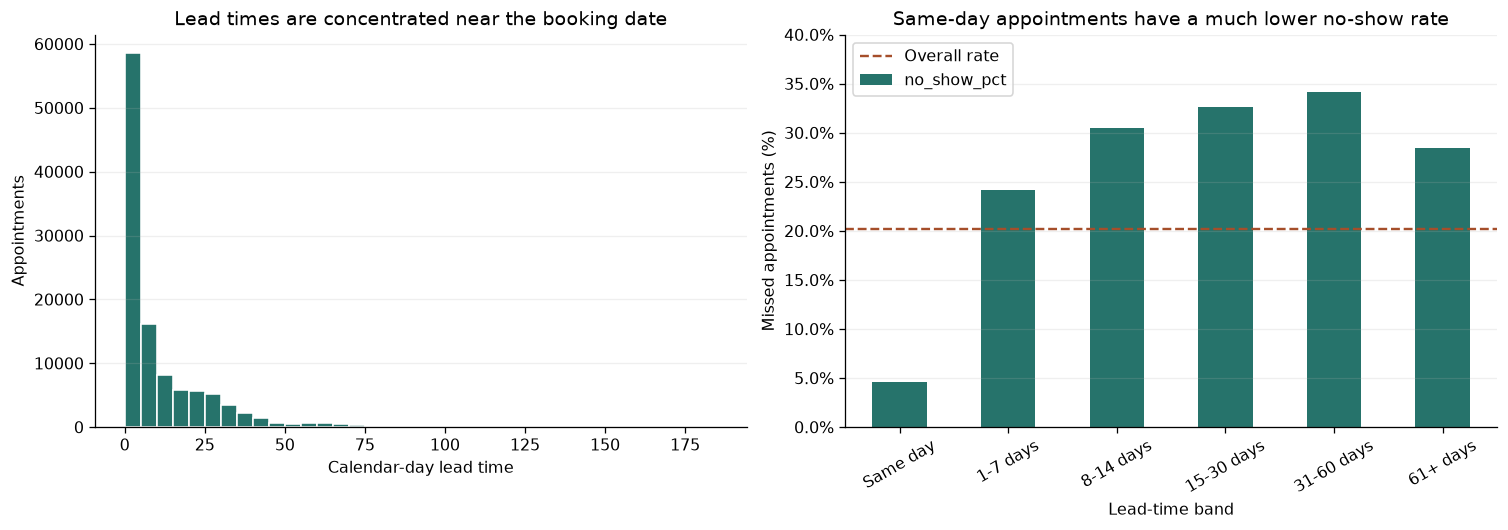

In [6]:
waiting_rates = group_rates(appointments, 'waiting_band')
display(waiting_rates.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
appointments['waiting_days'].plot.hist(ax=axes[0], bins=np.arange(0, 186, 5), color='#26736b', edgecolor='white')
label_plot(axes[0], 'Lead times are concentrated near the booking date', 'Calendar-day lead time', 'Appointments')
waiting_rates['no_show_pct'].plot.bar(ax=axes[1], color='#26736b', rot=30)
axes[1].axhline(overall_pct, color='#a54e2a', linestyle='--', label='Overall rate')
axes[1].set_ylim(0, 40)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
label_plot(axes[1], 'Same-day appointments have a much lower no-show rate', 'Lead-time band', 'Missed appointments (%)')
axes[1].legend()
fig.savefig(FIGURES / '03_lead_time.png', bbox_inches='tight')
plt.show()

**Finding.** Same-day appointments have a no-show rate of
4.65%, compared with
24.15% at 1–7 days and
34.15% at 31–60 days.
The 61+ day group falls to 28.45%, so this
relationship is not strictly increasing throughout the range. Group sizes and
case mix differ. The pattern describes the recorded scheduling process; it
does not prove that moving an appointment earlier would change attendance.

### 3. Recorded SMS receipt and attendance

Inspect the number of appointments in each SMS group before comparing rates.
The flag means an SMS was recorded; the dataset does not identify the time of
the message, whether it was read, or why one patient received a message and
another did not. Treat both groups as observational cohorts, not experimental
treatment and control groups.

,appointments,no_shows,no_show_rate,no_show_pct
sms_group,,,,
No SMS recorded,75039,12530,0.17,16.70
SMS recorded,35482,9784,0.28,27.57


,median,mean
sms_group,,
No SMS recorded,0.0,6.01
SMS recorded,14.0,19.02


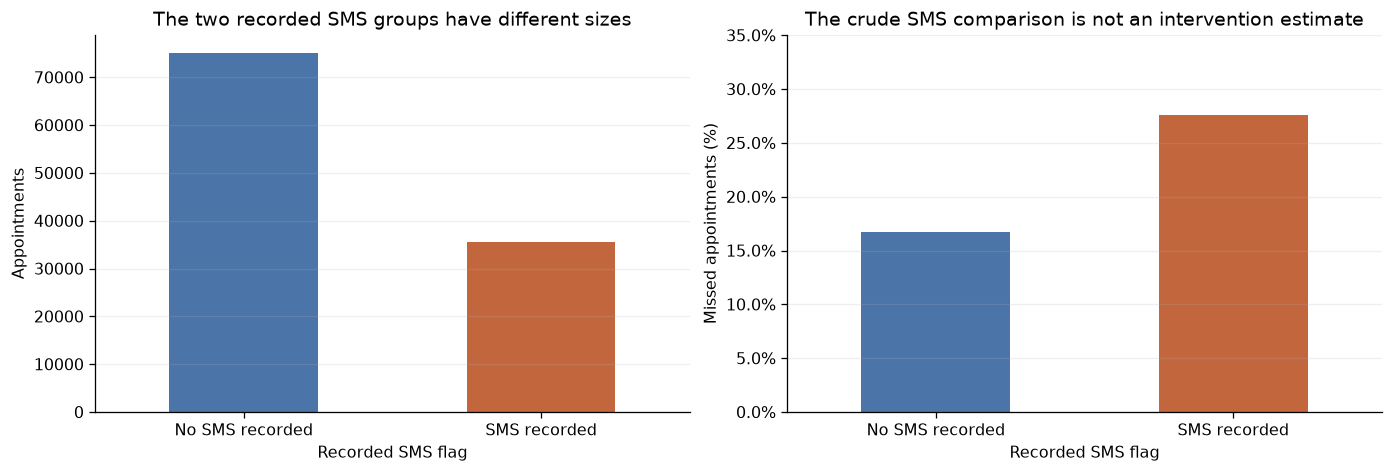

In [7]:
sms_rates = group_rates(appointments, 'sms_group')
display(sms_rates.round(2))
display(appointments.groupby('sms_group', observed=True)['waiting_days'].agg(['median', 'mean']).round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
sms_rates['appointments'].plot.bar(ax=axes[0], rot=0, color=['#4b75a8', '#c2673d'])
label_plot(axes[0], 'The two recorded SMS groups have different sizes', 'Recorded SMS flag', 'Appointments')
sms_rates['no_show_pct'].plot.bar(ax=axes[1], rot=0, color=['#4b75a8', '#c2673d'])
axes[1].set_ylim(0, 35)
axes[1].yaxis.set_major_formatter(PercentFormatter(100))
label_plot(axes[1], 'The crude SMS comparison is not an intervention estimate', 'Recorded SMS flag', 'Missed appointments (%)')
fig.savefig(FIGURES / '04_sms_crude.png', bbox_inches='tight')
plt.show()

**Finding.** The overall no-show rate is
27.57% among appointments with an SMS
recorded (35,482 appointments), compared
with 16.70% without one
(75,039 appointments).
This crude comparison cannot establish that reminders worsen attendance.
Booking lead time differs between these cohorts and provides a concrete
reason to inspect group composition before drawing conclusions.

### 4. Comparisons within lead-time bands and across age groups

Use the same lead-time bands for both SMS groups and retain every observed
denominator. An absent category is not a zero no-show rate: the same-day/SMS
combination has no observations. Its plot value is therefore missing. The
second plot compares age and lead time jointly; it shows where an apparent
age relationship coexists with differences in scheduling delay.

appointments  no_shows  no_show_rate  \
waiting_band sms_group                                               
Same day     No SMS recorded         38562      1792          0.05   
1-7 days     No SMS recorded         20637      5028          0.24   
             SMS recorded            11548      2744          0.24   
8-14 days    No SMS recorded          5021      1695          0.34   
             SMS recorded             7004      1969          0.28   
15-30 days   No SMS recorded          6851      2526          0.37   
             SMS recorded            10520      3135          0.30   
31-60 days   No SMS recorded          3224      1237          0.38   
             SMS recorded             5059      1592          0.31   
61+ days     No SMS recorded           744       252          0.34   
             SMS recorded             1351       344          0.25   

                              no_show_pct  
waiting_band sms_group                     
Same day     No SMS recorded         4.65  
1-7 days     No SMS recorded        24.36  
             SMS recorded           23.76  
8-14 days    No SMS recorded        33.76  
             SMS recorded           28.11  
15-30 days   No SMS recorded        36.87  
             SMS recorded           29.80  
31-60 days   No SMS recorded        38.37  
             SMS recorded           31.47  
61+ days     No SMS recorded        33.87  
             SMS recorded           25.46

sms_group,No SMS recorded,SMS recorded
waiting_band,,
Same day,38562.0,NaN
1-7 days,20637.0,11548.0
8-14 days,5021.0,7004.0
15-30 days,6851.0,10520.0
31-60 days,3224.0,5059.0
61+ days,744.0,1351.0


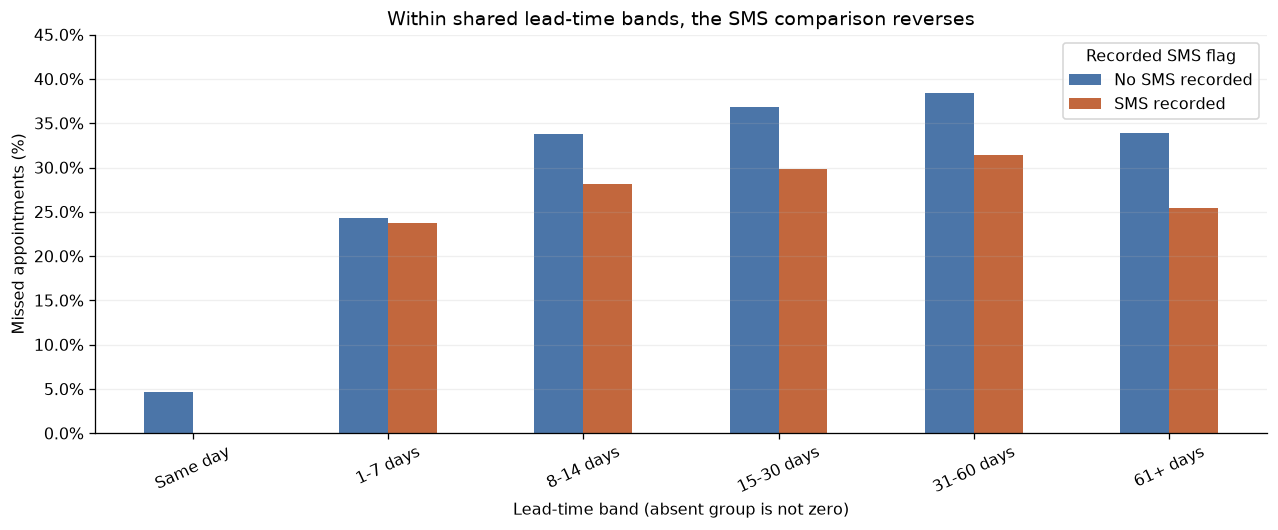

appointments  no_shows  no_show_rate  no_show_pct
age_band waiting_band                                                   
Under 18 Same day             11212       779          0.07         6.95
         1-7 days              6201      1667          0.27        26.88
         8-14 days             3078      1029          0.33        33.43
         15-30 days            4337      1525          0.35        35.16
         31-60 days            2332       904          0.39        38.77
         61+ days               218        92          0.42        42.20
18-34    Same day              8534       389          0.05         4.56
         1-7 days              6534      1942          0.30        29.72
         8-14 days             2980      1062          0.36        35.64
         15-30 days            4135      1595          0.39        38.57
         31-60 days            1776       705          0.40        39.70
         61+ days               285       119          0.42        41.75
35-49    Same day              7615       267          0.04         3.51
         1-7 days              6362      1620          0.25        25.46
         8-14 days             2418       722          0.30        29.86
         15-30 days            3493      1205          0.34        34.50
         31-60 days            1636       577          0.35        35.27
         61+ days               340        98          0.29        28.82
50-64    Same day              6974       245          0.04         3.51
         1-7 days              7823      1552          0.20        19.84
         8-14 days             2188       532          0.24        24.31
         15-30 days            3310       867          0.26        26.19
         31-60 days            1695       455          0.27        26.84
         61+ days               644       134          0.21        20.81
65+      Same day              4227       112          0.03         2.65
         1-7 days              5265       991          0.19        18.82
         8-14 days             1361       319          0.23        23.44
         15-30 days            2096       469          0.22        22.38
         31-60 days             844       188          0.22        22.27
         61+ days               608       153          0.25        25.16

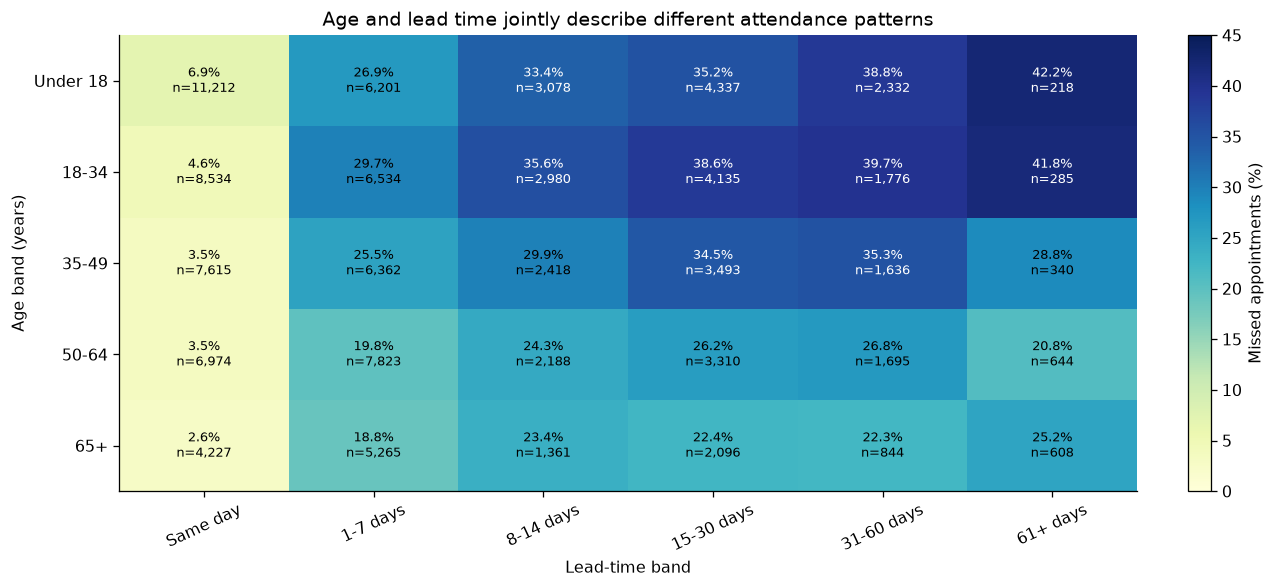

In [8]:
sms_by_wait = group_rates(appointments, ['waiting_band', 'sms_group'])
display(sms_by_wait.round(2))
rate_matrix = sms_by_wait['no_show_pct'].unstack('sms_group')
count_matrix = sms_by_wait['appointments'].unstack('sms_group')
display(count_matrix)
fig, ax = plt.subplots(figsize=(11, 4.5), constrained_layout=True)
rate_matrix.plot.bar(ax=ax, rot=25, color=['#4b75a8', '#c2673d'])
ax.set_ylim(0, 45)
ax.yaxis.set_major_formatter(PercentFormatter(100))
label_plot(ax, 'Within shared lead-time bands, the SMS comparison reverses', 'Lead-time band (absent group is not zero)', 'Missed appointments (%)')
ax.legend(title='Recorded SMS flag')
fig.savefig(FIGURES / '05_sms_by_lead_time.png', bbox_inches='tight')
plt.show()

joint = group_rates(appointments, ['age_band', 'waiting_band'])
display(joint.round(2))
joint_rates = joint['no_show_pct'].unstack('waiting_band')
joint_counts = joint['appointments'].unstack('waiting_band')
fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
shown = joint_rates.where(joint_counts >= 100)
image = ax.imshow(shown.to_numpy(), cmap='YlGnBu', vmin=0, vmax=45, aspect='auto')
ax.set_xticks(np.arange(len(shown.columns)), labels=shown.columns, rotation=25)
ax.set_yticks(np.arange(len(shown.index)), labels=shown.index)
for row in range(len(shown.index)):
    for col in range(len(shown.columns)):
        value = shown.iloc[row, col]
        n = joint_counts.iloc[row, col]
        label = f'{value:.1f}%\nn={int(n):,}' if pd.notna(value) else f'n={int(n):,} <100'
        ax.text(col, row, label, ha='center', va='center', fontsize=8,
                color='white' if pd.notna(value) and value > 30 else 'black')
label_plot(ax, 'Age and lead time jointly describe different attendance patterns', 'Lead-time band', 'Age band (years)')
ax.grid(False)
fig.colorbar(image, ax=ax, label='Missed appointments (%)')
fig.savefig(FIGURES / '06_age_by_lead_time.png', bbox_inches='tight')
plt.show()

**Finding.** Among all five lead-time bands where both SMS groups are observed,
the SMS-recorded group has a lower no-show rate than the no-SMS-recorded group.
There are no SMS-recorded appointments in the same-day band, which itself has
a very low no-show rate. Its inclusion in the no-SMS cohort partly explains
why the overall comparison runs in the opposite direction. This is an example
of an aggregated comparison changing after stratification, not proof of a
reminder effect. The bands are broad, other factors still differ, and SMS
timing is unknown. The age-by-lead-time table and heatmap further show that
comparing only one characteristic hides considerable variation.

Cells with fewer than 100 appointments are withheld from the heatmap's color
scale as a display convention, not as a statistical significance rule. All
observed counts and rates remain available in the table above.

<a id="conclusions"></a>
## Conclusions

In the cleaned snapshot, **22,314 of 110,521
appointments were missed (20.19%)**.

- **Age:** the 18–34 group has a higher descriptive no-show rate
  (23.97%) than the 65+ group
  (15.50%). Age alone does not explain attendance.
- **Lead time:** same-day appointments have a much lower rate
  (4.65%) than appointments booked 31–60
  calendar days ahead (34.15%). The pattern
  is not monotonic in the longest-delay band.
- **SMS:** the crude SMS association reverses within every shared lead-time
  band. Comparing the overall SMS percentages without considering scheduling
  differences would be misleading.

These findings answer the initial questions descriptively. They motivate
collecting richer scheduling and communication data and evaluating reminder
policies with an appropriate design; they do not justify changing clinical or
administrative policy on their own.

<a id="limitations"></a>
## Limitations and useful next steps

1. **Observational assignment and unknown SMS timing.** Neither SMS receipt nor
   lead time was randomized. Delivery timing, reading, appointment urgency and
   selection into reminders are unobserved. A causal evaluation would need a
   prospective design or defensible identification assumptions and richer data.
2. **Repeated patients.** The 110,521 appointments represent only
   62,298 distinct identifiers. Frequent attendees have
   more weight in appointment-level rates. No inferential intervals or
   independence-based significance claims are made; patient-level or clustered
   analyses would be useful for a different research question.
3. **Limited population and time coverage.** This is a limited clinic population's
   short 2016 appointment window. Results do not describe all of Brazil or current
   services. Wider time coverage and the data-collection rules would help.
4. **Measurement and exclusions.** Dates supply calendar-day lead time, not
   exact appointment times. Six invalid records were excluded; very high ages
   were retained. The snapshot does not explain corrections, cancellations,
   rescheduling or the appointment-labeling process.
5. **Unmeasured factors and grouping choices.** Transport, appointment purpose,
   urgency, work schedules and provider characteristics could matter. Age and
   lead-time bins lose information and are not a complete adjustment for
   confounding. Sensitivity to different bins, continuous-variable summaries
   and an explicit patient-level study would be useful follow-ups.

## Reproducibility and references

The required input is `data/noshowappointments-kagglev2-may-2016.csv`; its SHA-256
is verified at the start. All tables and figures are recomputed from that
snapshot. The notebook's cleaning and plotting helpers are embedded here, so
it can run without importing project-specific modules. Raw input data is
excluded from the submission; retrieval instructions are in the README.

- Udacity, *Course Overview*, supplied project instructions and rubric.
- Joni Hoppen, *Medical Appointment No Shows*, Kaggle, source description linked
  by the course. The analysis uses the course-supplied snapshot.
- Pandas documentation: datetime conversion, categorical grouping and named
  aggregation; API usage checked through Context7.

The original template tips have been replaced with the project's analysis and
explanations. No statistical test, predictive model or causal estimate is
claimed in this report.